## Pytorch로 ResNet 구현하기

In [96]:
#필요한 라이브러리 호출
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torchvision.models as models

import matplotlib.pyplot as plt
import numpy as np

import copy
from collections import namedtuple # 파이썬 자료형 tuple
import time
import random
import os

import cv2
from torch.utils.data import DataLoader, Dataset
from PIL import Image

device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')

이미지 데이터 전처리

In [97]:
class ImageTransform():
  def __init__(self, resize, mean, std):
    self.data_transform={
        # 훈련 이미지 데이터 전처리
        'train': transforms.Compose([
            transforms.RandomResizedCrop(resize, scale=(0.5, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize(mean, std)
        ]),
        #검증, 테스트 이미지 데이터 전처리
        'val': transforms.Compose([
            transforms.Resize(256),
            transforms.CenterCrop(resize),
            transforms.ToTensor(),
            transforms.Normalize(mean, std)
        ])
    }
  def __call__(self, img, phase):
    return self.data_transform[phase](img)

In [98]:
size=224
mean=(0.485,0.456,0.406)
std=(0.229,0.224,0.225)
batch_size=32

In [99]:
# 데이터셋 불러오기

# import zipfile

# 압축 파일 경로와 해제할 폴더 경로 설정
# dogs-vs-cats_path = './dogs-vs-cats.zip'
# dogs-vs-cats_unzip_path = './dogs-vs-cats'

#with zipfile.ZipFile(dogs-vs-cats_path , 'r') as zip_ref:
#    zip_ref.extractall(dogs-vs-cats_unzip_path )



In [100]:
cat_directory=r'./dogs-vs-cats/Cat/'
dog_directory=r'./dogs-vs-cats/Dog/'

import glob

# 폴더 안의 이미지 경로 가져오기
images_filepaths = (
    glob.glob(cat_directory + '*.jpg')
    + glob.glob(dog_directory + '*.jpg')
)
correct_images_filepaths = [
    i for i in images_filepaths
    if cv2.imread(i) is not None
]

In [101]:
# 훈련, 검증, 테스트 용도로 분리
random.seed(42)
random.shuffle(correct_images_filepaths)

train_images_filepaths=correct_images_filepaths[:400]
val_images_filepaths=correct_images_filepaths[400:-10]
test_images_filepaths=correct_images_filepaths[-10:]
print(len(train_images_filepaths),  #400
      len(val_images_filepaths),  #92
      len(test_images_filepaths)) #10


400 92 10


In [102]:
# 이미지에 대한 레이블 구분 -> 개 =1, 고양이=0
class DogvsCatDataset(Dataset):

  def __init__(self, file_list, transforms=None, phase='train'):
    self.file_list=file_list
    self.transform=transforms
    self.phase=phase

  def __len__(self):
    return len(self.file_list)

  def __getitem__(self, idx):
    img_path=self.file_list[idx]
    img=Image.open(img_path)
    img_transformed=self.transform(img, self.phase)

    label=img_path.split('/')[-1].split('.')[0]
    if label=='dog':
      label=1
    elif label=='cat':
      label=0
    return img_transformed, label



In [103]:
# 이미지 데이터셋 정의
train_dataset=DogvsCatDataset(train_images_filepaths, transforms=ImageTransform(size, mean, std), phase='train')
val_dataset=DogvsCatDataset(val_images_filepaths, transforms=ImageTransform(size, mean, std), phase='val')

index=0
print(train_dataset.__getitem__(index)[0].size())
print(train_dataset.__getitem__(index)[1])

torch.Size([3, 224, 224])
0


In [104]:
# 데이터셋의 데이터를 메모리로 불러오기
train_iterator=DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_iterator=DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
dataloader_dict={'train': train_iterator, 'val': val_iterator}

batch_iterator=iter(train_iterator)
inputs, label=next(batch_iterator)
print(inputs.size())
print(label)

torch.Size([32, 3, 224, 224])
tensor([1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1,
        0, 0, 1, 0, 1, 1, 1, 0])


기본 블록 정의: ResNet18, ResNet34 에서 사용되며 합성곱 3x3 두개로 구성됨

In [105]:
class BasicBlock(nn.Module):

  expansion=1

  def __init__(self, in_channels, out_channels, stride=1, downsample=False):
    super().__init__()
    self.conv1=nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
    self.bn1=nn.BatchNorm2d(out_channels)
    self.conv2=nn.Conv2d(out_channels, out_channels*self.expansion, kernel_size=3, stride=1, padding=1, bias=False)
    self.bn2=nn.BatchNorm2d(out_channels)
    self.relu=nn.ReLU(inplace=True)

    if downsample: # 다운 샘플
      conv=nn.Conv2d(in_channels, out_channels*self.expansion, kernel_size=1, stride=stride, bias=False)
      bn=nn.BatchNorm2d(out_channels)
      downsample=nn.Sequential(conv, bn)
    else:
      downsample=None
    self.downsample=downsample

  def forward(self, x): # identity mapping 적용
    i=x
    x=self.conv1(x)
    x=self.bn1(x)
    x=self.relu(x)
    x=self.conv2(x)
    x=self.bn2(x)

    if self.downsample is not None:
      i=self.downsample(i)

    x+=I
    x=self.relu(x)

    return x


병목 블록 bottleneck block 정의: ResNet50, ResNet101, ResNet152에서 사용되고, 1x1 3x3 1x1 conv로 구성됨

In [138]:
class Bottleneck(nn.Module):
  expansion=4

  def __init__(self, in_channels, out_channels, stride=1, downsample=False):
    super().__init__()
    self.conv1=nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, bias=False)
    self.bn1=nn.BatchNorm2d(out_channels)
    self.conv2=nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
    self.bn2=nn.BatchNorm2d(out_channels)
    self.conv3=nn.Conv2d(out_channels, out_channels*self.expansion, kernel_size=1, stride=1, bias=False)
    self.bn3=nn.BatchNorm2d(self.expansion*out_channels)
    self.relu=nn.ReLU(inplace=True)

    if downsample:
      conv=nn.Conv2d(in_channels, self.expansion*out_channels, kernel_size=1, stride=stride, bias=False)
      bn=nn.BatchNorm2d(self.expansion*out_channels)
      downsample=nn.Sequential(conv, bn)
    else:
      downsample=None
    self.downsample=downsample

  def forward(self, x):
    i=x
    x=self.conv1(x)
    x-self.bn1(x)
    x=self.relu(x)
    x=self.conv2(x)
    x=self.bn2(x)
    x=self.relu(x)
    x=self.conv3(x)
    x=self.bn3(x)

    if self.downsample is not None:
      i=self.downsample(i)

    x+=i
    x=self.relu(x)
    return x

ResNet 모델 네트워크

In [139]:
class ResNet(nn.Module):
  def __init__(self, config, output_dim, zero_init_residual=False):
    super().__init__()

    block, n_blocks, channels= config # resnet을 호출할 때 넘겨준 config 값들을 block, n_blocks, channels에 저장
    self.in_channels=channels[0]
    assert len(n_blocks)==len(channels) ==4

    self.conv1= nn.Conv2d(3, self.in_channels, kernel_size=7, stride=2, padding=3, bias=False)
    self.bn1=nn.BatchNorm2d(self.in_channels)
    self.relu = nn.ReLU(inplace=True)
    self.maxpool=nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

    self.layer1=self.get_resnet_layer(block, n_blocks[0], channels[0])
    self.layer2=self.get_resnet_layer(block, n_blocks[1], channels[1], stride=2)
    self.layer3=self.get_resnet_layer(block, n_blocks[2], channels[2], stride=2)
    self.layer4=self.get_resnet_layer(block, n_blocks[3], channels[3], stride=2)

    self.avgpool=nn.AdaptiveAvgPool2d((1,1))
    self.fc=nn.Linear(self.in_channels, output_dim)

    if zero_init_residual:
      for m in self.modules():
        if isinstance(m, Bottleneck):
          nn.init.constant_(m.bn3.weight,0)
        elif isinstance(m,BasicBlock):
          nn.init.constant_(m.bn2.weight,0)

  def get_resnet_layer(self, block, n_blocks, channels, stride=1):
    layers=[]
    if self.in_channels != block.expansion*channels:
      downsample=True
    else:
      downsample=False

    layers.append(block(self.in_channels, channels, stride, downsample))
    for i in range(1, n_blocks): # n_blocks 만큼 추가
      layers.append(block(block.expansion*channels, channels))

    self.in_channels=block.expansion*channels
    return nn.Sequential(*layers)

  def forward(self, x):
    x=self.conv1(x)
    x=self.bn1(x)
    x=self.relu(x)
    x=self.maxpool(x)
    x=self.layer1(x)
    x=self.layer2(x)
    x=self.layer3(x)
    x=self.layer4(x)
    x=self.avgpool(x)
    h=x.view(x.shape[0],-1)
    x=self.fc(h)

    return x, h


In [140]:
ResNetConfig=namedtuple('ResNetConfig', ['block', 'n_blocks', 'channels'])

In [141]:
resnet18_config=ResNetConfig(BasicBlock, [2,2,2,2], [64,128,256,512])
resnet34_config=ResNetConfig(BasicBlock, n_blocks=[3,4,6,3], channels=[64,128,256,512])
resnet50_config=ResNetConfig(Bottleneck, n_blocks=[3,4,6,3], channels=[64,128,256,512])
resnet101_config=ResNetConfig(Bottleneck, n_blocks=[3,4,23,3], channels=[64,128,256,512])
resnet152_config=ResNetConfig(Bottleneck, n_blocks=[3,8,36,3], channels=[64,128,256,512])

In [142]:
pretrained_model=models.resnet18(pretrained=True)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [143]:
print(pretrained_model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [144]:
OUTPUT_DIM=2 # 두개의 클래스 사용(개 / 고양이)
model=ResNet(resnet50_config, OUTPUT_DIM)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [145]:
# 옵티마이저, 손실함수 정의
optimizer=optim.Adam(model.parameters(), lr=1e-7)
criterion=nn.CrossEntropyLoss()
# 스케줄러
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10,
    eta_min=1e-6
)
model=model.to(device)
criterion=criterion.to(device)

모델 학습도 측정 함수 정의

In [151]:
def calculate_topk_accurarcy(y_pred, y, k=2):
  with torch.no_grad():
    batch_size=y.shape[0]
    _, top_pred= y_pred.topk(k, 1) # 출력에서 가장 확률이 높은 값의 인덱스를 반환
    top_pred= top_pred.t()
    correct=top_pred.eq(y.view(1,-1).expand_as(top_pred))
    correct_1=correct[:1].reshape(-1).float().sum(0, keepdim=True)
    correct_k=correct[:k].reshape(-1).float().sum(0, keepdim=True)
    acc_1=correct_1/batch_size
    acc_k=correct_k/batch_size

  return acc_1, acc_k

모델 학습 함수 정의

In [152]:
def train(model, iterator, optimizer, criterion, scheduler, device):
  epoch_loss=0
  epoch_acc_1=0
  epoch_acc_5=0

  model.train()
  for(x,y) in iterator:
    x=x.to(device)
    y=y.to(device)

    optimizer.zero_grad()
    y_pred=model(x)
    loss=criterion(y_pred[0],y)

    acc_1, acc_5=calculate_topk_accurarcy(y_pred[0], y)
    loss.backward()
    optimizer.step()

    epoch_loss+=loss.item()
    epoch_acc_1+=acc_1.item()
    epoch_acc_5+=acc_5.item()

  epoch_loss /=len(iterator)
  epoch_acc_1 /=len(iterator)
  epoch_acc_5 /=len(iterator)
  return epoch_loss, epoch_acc_1, epoch_acc_5



모델 평가 함수 정의

In [153]:
def evaluate(model, iterator, criterion, device):
  epoch_loss=0
  epoch_acc_1=0
  epoch_acc_5=0

  model.eval()
  with torch.no_grad():
    for (x,y) in iterator:
      x=x.to(device)
      y=y.to(device)
      y_pred=model(x)
      loss=criterion(y_pred[0],y)

      acc_1, acc_5=calculate_topk_accurarcy(y_pred[0], y)
      epoch_loss+=loss.item()
      epoch_acc_1+=acc_1.item()
      epoch_acc_5+=acc_5.item()

  epoch_loss /=len(iterator)
  epoch_acc_1 /=len(iterator)
  epoch_acc_5 /=len(iterator)
  return epoch_loss, epoch_acc_1, epoch_acc_5

In [154]:
# 모델 학습 시간 측정 함수 정의
def epoch_time(start_time, end_time):
  elapsed_time=end_time-start_time
  elapsed_mins=int(elapsed_time/60)
  elapsed_secs=int(elapsed_time-(elapsed_mins*60))
  return elapsed_mins, elapsed_secs

모델 학습

In [155]:
best_valid_loss=float('inf')
EPOCHS=10

for epoch in range(EPOCHS):
  start_time=time.monotonic()
  train_loss, train_acc_1, train_acc_5= train(model, train_iterator, optimizer,
                                              criterion, scheduler, device)
  valid_loss, valid_acc_1, valid_acc_5=evaluate(model, val_iterator, criterion, device)

  if valid_loss< best_valid_loss:
    best_valid_loss=valid_loss
    torch.save(model.state_dict(), './ResNet-model.pt')
  end_time=time.monotonic()
  epoch_mins, epoch_secs=epoch_time(start_time, end_time)

  print(f'Epoch: {epoch+1:02} | Epoch Time: {epoch_mins}m {epoch_secs}s')
  print(f'\tTrain Loss: {train_loss:.3f} | Train @1: {train_acc_1*100:6.2f}% | Train @5: {train_acc_5*100:6.2f}%')
  print(f'\tValid Loss: {valid_loss:.3f} | Train @1: {valid_acc_1*100:6.2f}% | Train @5: {valid_acc_5*100:6.2f}%')


Epoch: 01 | Epoch Time: 0m 6s
	Train Loss: 0.706 | Train @1:  50.48% | Train @5: 100.00%
	Valid Loss: 0.696 | Train @1:  48.81% | Train @5: 100.00%
Epoch: 02 | Epoch Time: 0m 6s
	Train Loss: 0.709 | Train @1:  49.76% | Train @5: 100.00%
	Valid Loss: 0.711 | Train @1:  48.81% | Train @5: 100.00%
Epoch: 03 | Epoch Time: 0m 6s
	Train Loss: 0.707 | Train @1:  48.56% | Train @5: 100.00%
	Valid Loss: 0.730 | Train @1:  48.81% | Train @5: 100.00%
Epoch: 04 | Epoch Time: 0m 6s
	Train Loss: 0.698 | Train @1:  50.96% | Train @5: 100.00%
	Valid Loss: 0.716 | Train @1:  48.81% | Train @5: 100.00%
Epoch: 05 | Epoch Time: 0m 6s
	Train Loss: 0.707 | Train @1:  47.60% | Train @5: 100.00%
	Valid Loss: 0.707 | Train @1:  48.81% | Train @5: 100.00%
Epoch: 06 | Epoch Time: 0m 7s
	Train Loss: 0.700 | Train @1:  49.28% | Train @5: 100.00%
	Valid Loss: 0.698 | Train @1:  50.89% | Train @5: 100.00%
Epoch: 07 | Epoch Time: 0m 8s
	Train Loss: 0.694 | Train @1:  50.24% | Train @5: 100.00%
	Valid Loss: 0.693 | Tr

테스트 데이터셋을 이용한 모델 예측

In [157]:
import pandas as pd

id_list = []
pred_list = []
_id = 0

with torch.no_grad():
    for test_path in test_images_filepaths:
        img = Image.open(test_path)
        _id = test_path.split('/')[-1].split('.')[1]
        transform = ImageTransform(size, mean, std)
        img = transform(img, phase='val')

        img = img.unsqueeze(0)
        img = img.to(device)

        model.eval()
        outputs = model(img)
        preds = F.softmax(outputs[0], dim=1)[:, 1].tolist()

        id_list.append(_id)
        pred_list.append(preds[0])

res = pd.DataFrame({
    'id': id_list,
    'label': pred_list
})

res.sort_values(by='id', inplace=True)
res.reset_index(drop=True, inplace=True)

res.to_csv('./ResNet.csv', index=False)
res.head(10)

,id,label
0,143,0.448139
1,149,0.742240
2,16,0.481382
3,190,0.402678
4,210,0.473027
5,220,0.419860
6,25,0.572359
7,44,0.382142
8,56,0.398566
9,66,0.399157


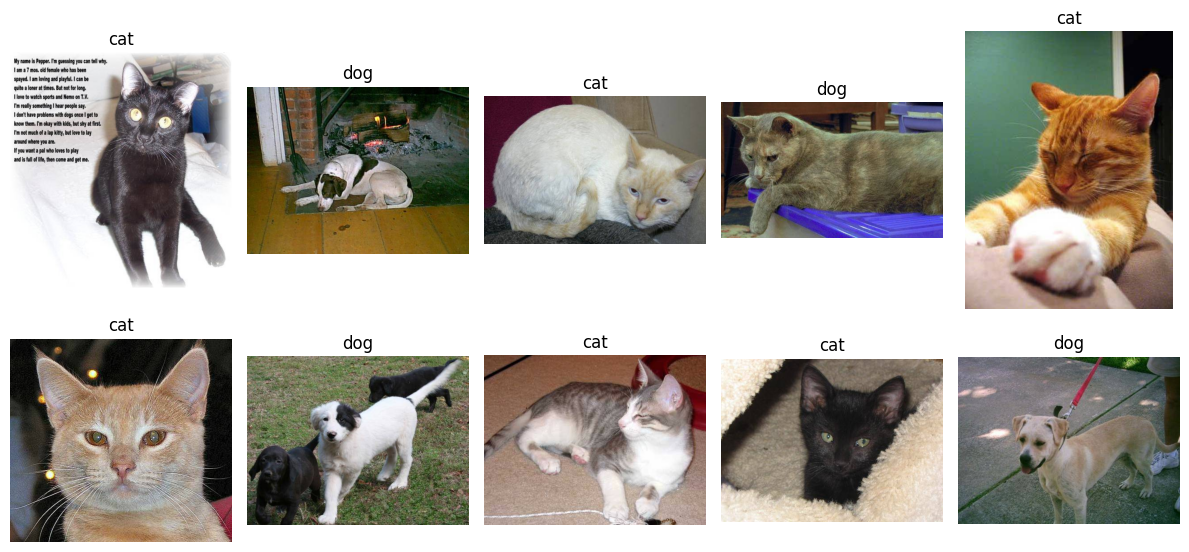

In [158]:
class_ = classes = {0: 'cat', 1: 'dog'}

def display_image_grid(images_filepaths, predicted_labels=(), cols=5):
    rows = len(images_filepaths) // cols
    figure, ax = plt.subplots(nrows=rows, ncols=cols, figsize=(12, 6))

    for i, image_filepath in enumerate(images_filepaths):
        image = cv2.imread(image_filepath)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        a = random.choice(res['id'].values)
        label = res.loc[res['id'] == a, 'label'].values[0]

        if label >= 0.5:
            label = 1
        else:
            label = 0

        ax.ravel()[i].imshow(image)
        ax.ravel()[i].set_title(class_[label])
        ax.ravel()[i].set_axis_off()

    plt.tight_layout()
    plt.show()

display_image_grid(test_images_filepaths)